# Task 2: Exploratory Data Analysis

**Goal:** explore the cleaned Netflix dataset from Task 1 to find trends, patterns and insights.

**Workflow**
1. Analyze dataset structure and statistics
2. Study content distribution by type
3. Identify top countries and categories
4. Create visualizations for key metrics
5. Summarize findings

**Input:** `netflix_cleaned.csv` (output of Task 1). Charts are also saved to a `charts/` folder for the submission screenshots.

## Setup

In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Consistent colors: each content type keeps the same color in every chart
BLUE, ORANGE = "#2a78d6", "#eb6834"
TYPE_COLORS = {"Movie": BLUE, "TV Show": ORANGE}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"

sns.set_theme(style="white")
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": GRID, "axes.labelcolor": MUTED,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.titleweight": "bold", "axes.titlesize": 13, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "figure.dpi": 110,
})

os.makedirs("charts", exist_ok=True)
def save(fig, name):
    fig.savefig(f"charts/{name}.png", bbox_inches="tight", dpi=150)

## Step 1: Analyze dataset structure and statistics

In [3]:
df = pd.read_csv("netflix_cleaned.csv", parse_dates=["date_added"])
df["audience"] = pd.Categorical(
    df["audience"], ["Little Kids", "Older Kids", "Teens", "Adults", "Unrated"], ordered=True
)
print("Shape:", df.shape)
print("Date range added:", df["date_added"].min().date(), "to", df["date_added"].max().date())
print("Release years:", df["release_year"].min(), "to", df["release_year"].max())
df.head(3)

Shape: (8786, 26)
Date range added: 2008-01-01 to 2021-09-25
Release years: 1925 to 2021


,show_id,type,title,director,country,date_added,year_added,month_added,month_name_added,weekday_added,...,duration_unit,movie_minutes,tv_seasons,listed_in,primary_genre,genre_count,director_missing,country_missing,title_format_issue,added_before_release
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2021,9,September,Saturday,...,min,90.0,NaN,Documentaries,Documentaries,1,False,False,False,False
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,9,September,Friday,...,season,NaN,1.0,"Crime TV Shows, International TV Shows, TV Act...",Crime TV Shows,3,False,False,False,False
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,9,September,Friday,...,season,NaN,1.0,"TV Dramas, TV Horror, TV Mysteries",TV Dramas,3,False,False,False,False


In [4]:
# Numeric summary
df[["release_year", "year_added", "years_to_netflix", "movie_minutes", "tv_seasons", "genre_count"]].describe().round(1).T

,count,mean,std,min,25%,50%,75%,max
release_year,8786.0,2014.2,8.8,1925.0,2013.0,2017.0,2019.0,2021.0
year_added,8786.0,2018.9,1.6,2008.0,2018.0,2019.0,2020.0,2021.0
years_to_netflix,8786.0,4.7,8.8,-3.0,0.0,1.0,5.0,93.0
movie_minutes,6123.0,99.6,28.3,3.0,87.0,98.0,114.0,312.0
tv_seasons,2663.0,1.8,1.6,1.0,1.0,1.0,2.0,17.0
genre_count,8786.0,2.2,0.8,1.0,2.0,2.0,3.0,3.0


In [5]:
# Categorical summary
df[["type", "country", "rating", "audience", "primary_genre", "director"]].describe().T

,count,unique,top,freq
type,8786,2,Movie,6123
country,8786,86,United States,3240
rating,8786,14,TV-MA,3204
audience,8786,5,Adults,4005
primary_genre,8786,36,Dramas,1597
director,8786,4528,Unknown,2587


**Observations**
- 8,786 titles, added to Netflix between January 2008 and **25 September 2021**. Because 2021 stops in September, it is a partial year and should not be compared directly with full years.
- Half of all titles were released in 2017 or later, and about 70% in 2015 or later. The catalog leans heavily toward recent content.
- The most common director value is "Unknown" (missing data flagged in Task 1), so director analysis below excludes it.

## Step 2: Content distribution by type

In [6]:
type_counts = df["type"].value_counts()
type_pct = (type_counts / len(df) * 100).round(1)
pd.DataFrame({"titles": type_counts, "percent": type_pct})

,titles,percent
type,,
Movie,6123,69.7
TV Show,2663,30.3


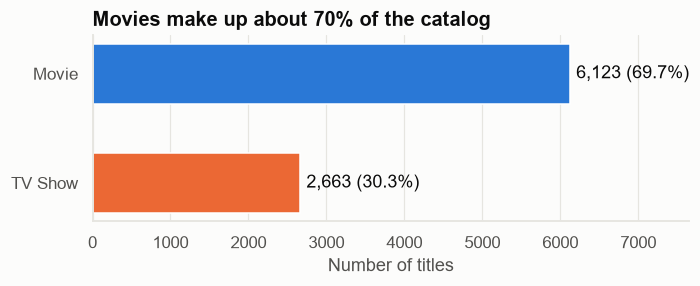

In [7]:
fig, ax = plt.subplots(figsize=(7, 2.2))
ax.barh(type_counts.index[::-1], type_counts.values[::-1],
        color=[TYPE_COLORS[t] for t in type_counts.index[::-1]], height=0.55)
for i, t in enumerate(type_counts.index[::-1]):
    ax.text(type_counts[t] + 80, i, f"{type_counts[t]:,} ({type_pct[t]}%)", va="center", color=INK)
ax.set_title("Movies make up about 70% of the catalog", loc="left")
ax.set_xlim(0, type_counts.max() * 1.25)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Number of titles")
save(fig, "01_type_split"); plt.show()

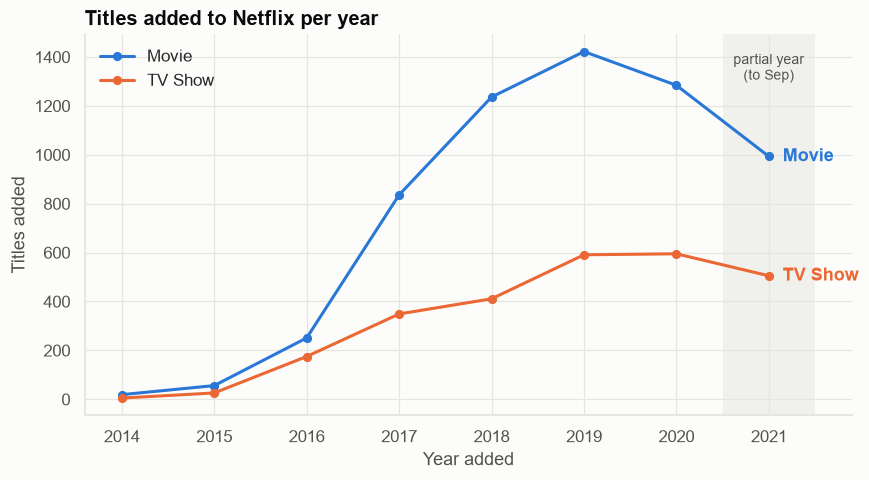

type,Movie,TV Show,tv_share_pct
year_added,,,
2014,19,5,20.8
2015,56,26,31.7
2016,251,175,41.1
2017,836,349,29.5
2018,1236,411,25.0
2019,1422,591,29.4
2020,1284,595,31.7
2021,993,505,33.7


In [8]:
# Titles added per year, by type (2021 is partial: data ends in September)
added = pd.crosstab(df["year_added"], df["type"]).loc[2014:]

fig, ax = plt.subplots(figsize=(9, 4.5))
for t in ["Movie", "TV Show"]:
    ax.plot(added.index, added[t], color=TYPE_COLORS[t], lw=2, marker="o", ms=5, label=t)
    ax.text(added.index[-1] + 0.15, added[t].iloc[-1], t, color=TYPE_COLORS[t], va="center", fontweight="bold")
ax.axvspan(2020.5, 2021.5, color=GRID, alpha=0.5, lw=0)
ax.text(2021, ax.get_ylim()[1] * 0.95, "partial year\n(to Sep)", ha="center", va="top", color=MUTED, fontsize=9)
ax.set_title("Titles added to Netflix per year", loc="left")
ax.set_xlabel("Year added"); ax.set_ylabel("Titles added")
ax.legend(frameon=False, loc="upper left")
ax.set_xlim(2013.6, 2021.9)
save(fig, "02_added_per_year"); plt.show()

added.assign(tv_share_pct=(added["TV Show"] / added.sum(axis=1) * 100).round(1))

**Observations**
- Additions grew sharply from 2016 and peaked in **2019** (about 2,000 titles).
- Movie additions fell after 2019, while TV Show additions held steady. The TV share of new additions rose from about 23% in 2017 to about 32% in 2020 and 34% in 2021.
- 2021 looks lower only because the data ends in September.

Median years from release to Netflix:
type
Movie      2.0
TV Show    0.0
Name: years_to_netflix, dtype: float64


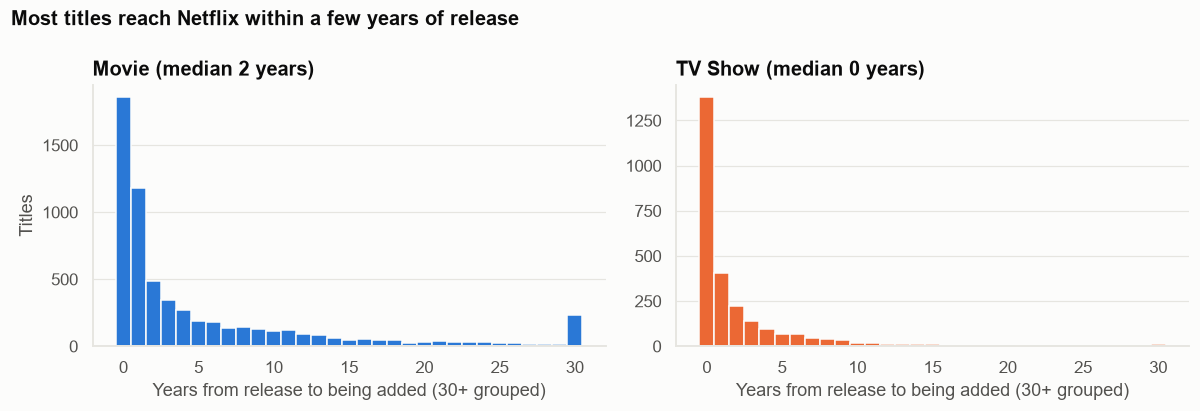

In [9]:
# How old is content when it reaches Netflix?
print("Median years from release to Netflix:")
print(df.groupby("type")["years_to_netflix"].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharex=True)
bins = np.arange(-0.5, 31.5, 1)
for ax, t in zip(axes, ["Movie", "TV Show"]):
    vals = df.loc[df["type"] == t, "years_to_netflix"].clip(upper=30)
    ax.hist(vals, bins=bins, color=TYPE_COLORS[t], edgecolor="#fcfcfb", linewidth=1)
    ax.set_title(f"{t} (median {vals.median():.0f} years)", loc="left")
    ax.set_xlabel("Years from release to being added (30+ grouped)")
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Titles")
fig.suptitle("Most titles reach Netflix within a few years of release", x=0.01, ha="left",
             fontweight="bold", fontsize=13, color=INK)
fig.tight_layout()
save(fig, "03_years_to_netflix"); plt.show()

**Observation:** TV Shows typically arrive the same year they are released (median 0 years), while Movies arrive a median of 2 years after release. Netflix licenses a long tail of older films, but its series catalog is mostly current.

## Step 3: Top countries and categories

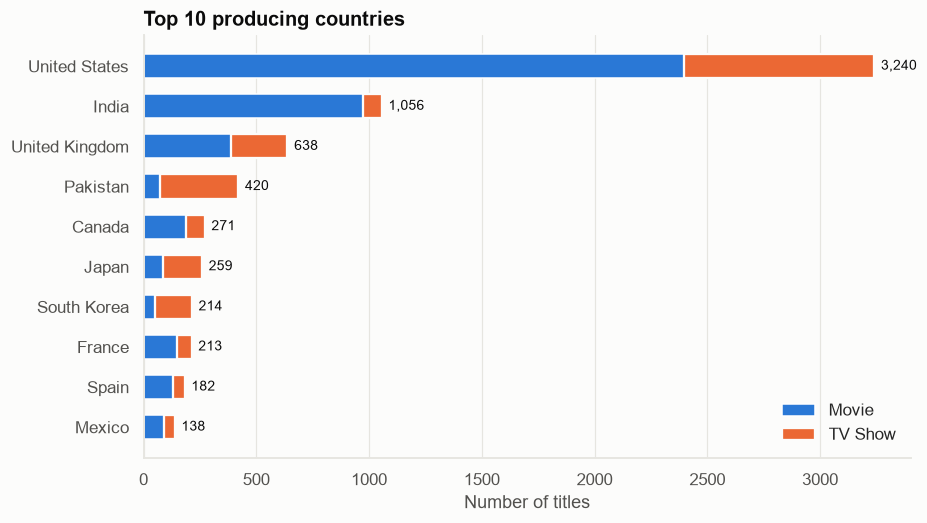

type,Movie,TV Show,total,tv_share_pct
country,,,,
United States,2395,845,3240,26.0
India,975,81,1056,8.0
United Kingdom,387,251,638,39.0
Pakistan,71,349,420,83.0
Canada,187,84,271,31.0
Japan,87,172,259,66.0
South Korea,49,165,214,77.0
France,148,65,213,31.0
Spain,129,53,182,29.0


In [10]:
known = df[df["country"] != "Unknown"]
top_countries = known["country"].value_counts().head(10)
country_type = pd.crosstab(known["country"], known["type"]).loc[top_countries.index]

fig, ax = plt.subplots(figsize=(9, 5))
y = np.arange(len(country_type))[::-1]
ax.barh(y, country_type["Movie"], color=BLUE, height=0.6, label="Movie")
ax.barh(y, country_type["TV Show"], left=country_type["Movie"], color=ORANGE, height=0.6,
        label="TV Show", edgecolor="#fcfcfb", linewidth=1.5)
ax.set_yticks(y, country_type.index)
for yi, total in zip(y, top_countries.values):
    ax.text(total + 30, yi, f"{total:,}", va="center", color=INK, fontsize=9)
ax.set_title("Top 10 producing countries", loc="left")
ax.set_xlabel("Number of titles")
ax.grid(axis="y", visible=False)
ax.legend(frameon=False, loc="lower right")
save(fig, "04_top_countries"); plt.show()

country_type.assign(total=top_countries, tv_share_pct=(country_type["TV Show"] / top_countries * 100).round(0))

**Observations**
- The United States leads with about 37% of titles with a known country, followed by India and the United Kingdom.
- Country mix differs sharply by type. India is over 90% Movies, while Pakistan, Japan and South Korea are mostly TV Shows (Japanese anime and Korean dramas are the likely drivers).
- Note: the `country` column holds one country per title in this file, so co-productions count only toward the listed country.

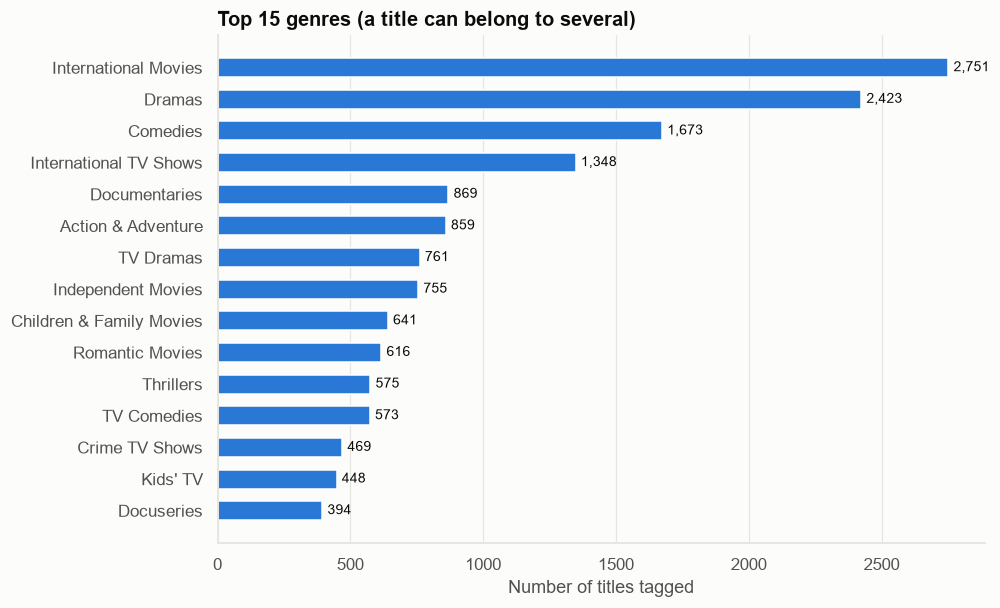

In [11]:
# Genres: each title can have several, so split them out first
genres = df.assign(genre=df["listed_in"].str.split(", ")).explode("genre")
top_genres = genres["genre"].value_counts().head(15)

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top_genres.index[::-1], top_genres.values[::-1], color=BLUE, height=0.6)
for i, v in enumerate(top_genres.values[::-1]):
    ax.text(v + 20, i, f"{v:,}", va="center", color=INK, fontsize=9)
ax.set_title("Top 15 genres (a title can belong to several)", loc="left")
ax.set_xlabel("Number of titles tagged")
ax.grid(axis="y", visible=False)
save(fig, "05_top_genres"); plt.show()

In [12]:
# Top genres within each type
for t in ["Movie", "TV Show"]:
    print(f"\nTop 5 {t} genres:")
    print(genres.loc[genres["type"] == t, "genre"].value_counts().head(5).to_string())


Top 5 Movie genres:
genre
International Movies    2751
Dramas                  2423
Comedies                1673
Documentaries            869
Action & Adventure       859

Top 5 TV Show genres:
genre
International TV Shows    1348
TV Dramas                  761
TV Comedies                573
Crime TV Shows             469
Kids' TV                   448


**Observations**
- "International Movies" is the single most common tag (about 31% of all titles), which matches the strong presence of India and other non-US countries.
- Dramas and Comedies dominate both Movies and TV Shows.
- Documentaries and Children & Family content are sizable niches.

In [13]:
# Top directors (excluding missing)
df.loc[df["director"] != "Unknown", "director"].value_counts().head(10)

director
Rajiv Chilaka             20
Raúl Campos, Jan Suter    18
Alastair Fothergill       18
Suhas Kadav               16
Marcus Raboy              16
Jay Karas                 14
Cathy Garcia-Molina       13
Youssef Chahine           12
Martin Scorsese           12
Jay Chapman               12
Name: count, dtype: int64

**Observation:** no director dominates; the most frequent has 20 titles. Several top names are associated with children's animation (for example Rajiv Chilaka) and stand-up comedy specials.

## Step 4: Visualizations for key metrics

### Audience ratings by type

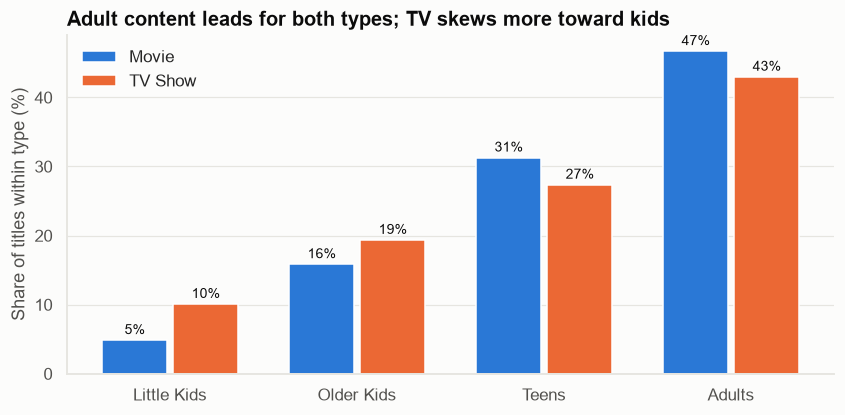

In [14]:
aud = pd.crosstab(df["type"], df["audience"], normalize="index") * 100
aud = aud.drop(columns="Unrated")

fig, ax = plt.subplots(figsize=(9, 4))
x = np.arange(len(aud.columns)); w = 0.38
for i, t in enumerate(["Movie", "TV Show"]):
    bars = ax.bar(x + (i - 0.5) * w, aud.loc[t], width=w - 0.03, color=TYPE_COLORS[t], label=t)
    ax.bar_label(bars, fmt="%.0f%%", fontsize=9, color=INK, padding=2)
ax.set_xticks(x, aud.columns)
ax.set_ylabel("Share of titles within type (%)")
ax.set_title("Adult content leads for both types; TV skews more toward kids", loc="left")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False)
save(fig, "06_audience_by_type"); plt.show()

**Observation:** about 45% of the catalog is rated for adults (TV-MA, R, NC-17). TV Shows have roughly double the share of "Little Kids" content compared with Movies (10% vs 5%).

### Duration

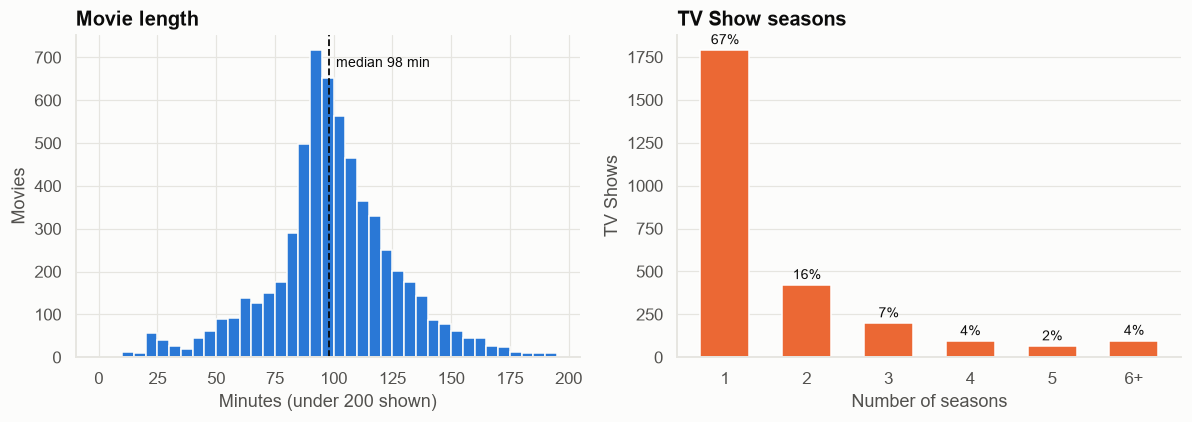

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

movies = df.loc[df["type"] == "Movie", "movie_minutes"]
axes[0].hist(movies, bins=np.arange(0, 200, 5), color=BLUE, edgecolor="#fcfcfb", linewidth=1)
axes[0].axvline(movies.median(), color=INK, lw=1.2, ls="--")
axes[0].text(movies.median() + 3, axes[0].get_ylim()[1] * 0.9, f"median {movies.median():.0f} min", color=INK, fontsize=9)
axes[0].set_title("Movie length", loc="left")
axes[0].set_xlabel("Minutes (under 200 shown)"); axes[0].set_ylabel("Movies")

seasons = df.loc[df["type"] == "TV Show", "tv_seasons"].clip(upper=6).value_counts().sort_index()
labels = [str(int(s)) if s < 6 else "6+" for s in seasons.index]
bars = axes[1].bar(labels, seasons.values, color=ORANGE, width=0.6)
axes[1].bar_label(bars, labels=[f"{v / seasons.sum() * 100:.0f}%" for v in seasons.values], fontsize=9, color=INK, padding=2)
axes[1].set_title("TV Show seasons", loc="left")
axes[1].set_xlabel("Number of seasons"); axes[1].set_ylabel("TV Shows")
axes[1].grid(axis="x", visible=False)

fig.tight_layout()
save(fig, "07_duration"); plt.show()

**Observations**
- Movies cluster tightly around 90 to 115 minutes (median 98).
- About two thirds of TV Shows have only **one season**. This could reflect new originals, limited series, or shows that were not renewed.

### When are titles added?

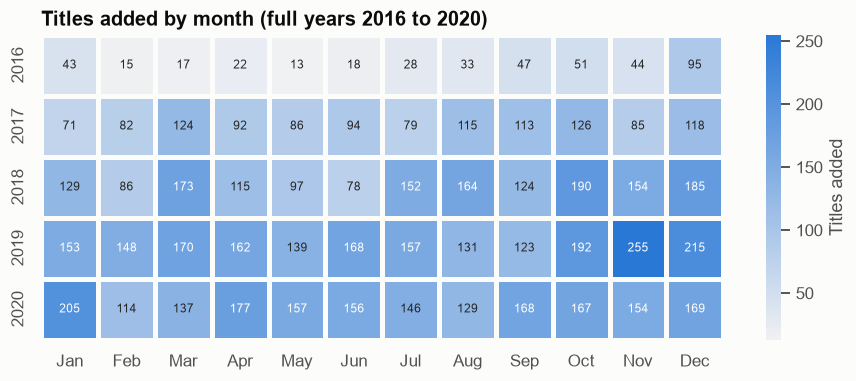

In [16]:
months = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
heat = pd.crosstab(df["year_added"], df["month_name_added"]).reindex(columns=months).loc[2016:2020]
heat.columns = [m[:3] for m in months]

fig, ax = plt.subplots(figsize=(10, 3.6))
sns.heatmap(heat, cmap=sns.light_palette(BLUE, as_cmap=True), annot=True, fmt="d",
            linewidths=2, linecolor="#fcfcfb", cbar_kws={"label": "Titles added"}, ax=ax,
            annot_kws={"fontsize": 8})
ax.set_title("Titles added by month (full years 2016 to 2020)", loc="left")
ax.set_xlabel(""); ax.set_ylabel("")
save(fig, "08_month_heatmap"); plt.show()

**Observation:** seasonality is mild. Across 2016 to 2020, October to December were the busiest months for additions and February the quietest, but year-to-year growth matters far more than the month.

## Step 5: Summary of findings

1. **Movies dominate the catalog** (about 70%), but TV Shows are a growing share of new additions, rising from about 23% in 2017 to about 34% in 2021.
2. **Content additions peaked in 2019** (about 2,000 titles) and declined in 2020, driven by fewer movie additions. 2021 data is partial (to September).
3. **The catalog is recent.** Half of all titles were released in 2017 or later. TV Shows usually arrive the year they are released; movies a median of 2 years after.
4. **The United States, India and the United Kingdom** are the top sources. India's content is almost all movies, while Japan, South Korea and Pakistan contribute mainly TV Shows.
5. **International content, Dramas and Comedies** are the most common genres.
6. **Adult-rated content is the largest audience group** (about 45%). TV has a higher share of young children's content than film.
7. **Typical formats:** a movie runs about 98 minutes; two thirds of TV Shows have a single season.
8. **Mild seasonality:** slightly more additions in October to December, fewest in February.

**Limitations**
- 2021 is a partial year.
- Each title lists one country, so co-productions are undercounted for secondary countries.
- About 29% of titles have no director listed (mostly TV Shows), so director findings are limited.
- This is a snapshot of the catalog as of 2021, not viewing data, so it shows what Netflix offers, not what people watch.

**Next steps:** these findings feed Task 4 (trend forecasting using additions per year) and Task 5 (classifying Movie vs TV Show, where country, rating and genre are clearly useful features).